# Autoencoder on IFCNet: BIM object Anomaly detection + Similarity
Team group2_hackathon · AI Methods I hackathon · Monday

## 0. Setup

In [1]:
from pathlib import Path
import random
import numpy as np
import torch
from PIL import Image
import random
import numpy as np
import torch
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 1. The data

In [2]:
from pathlib import Path
ROOT = Path("../../data/IFCNetCorePng")      # extracted dataset root
if not ROOT.exists():                        # zip extracted straight into data/ (no IFCNetCorePng folder)
    ROOT = Path("../../data")
assert any(ROOT.glob("Ifc*")) or any(ROOT.glob("ifcnet_*px_cache.pt")), f"IFCNet data not found in {ROOT.resolve()}"
IMG = 64                       # image size in pixels
VIEWS = ["0", "3", "6"]        # 3 of the 12 rendered views per object
MAX_OBJ_PER_CLASS = 300        # small first run

CACHE = ROOT / f"ifcnet_{IMG}px_cache.pt"   # tensors saved by the first run

if CACHE.exists():
    # fast path: reuse the tensors built on an earlier run (delete the file to rebuild)
    d = torch.load(CACHE)
    X_train, y_train, X_val, y_val = d["X_train"], d["y_train"], d["X_val"], d["y_val"]
    X_test, y_test, classes = d["X_test"], d["y_test"], d["classes"]
    print("loaded", CACHE)
else:
    # 1) Find all images. Path pattern: data/<IfcClass>/<train|test>/<object_id>.<view>.png
    pngs = sorted(ROOT.rglob("*.png"))
    print(len(pngs), "png files")

    def info(p):
        rel = p.relative_to(ROOT).parts
        cls, split = rel[0], rel[1]
        obj, view = p.stem.rsplit(".", 1)
        return cls, split, obj, view

    # 2) Group the chosen views of each object
    groups = {}
    for p in pngs:
        cls, split, obj, view = info(p)
        if view in VIEWS:
            groups.setdefault((cls, split, obj), []).append(p)

    classes = sorted({k[0] for k in groups})
    print(len(classes), "classes:", classes)

    # 3) Load as 64x64 greyscale, values 0-1, object bright on dark background
    def load(split):
        X, y, ids = [], [], []
        for c_i, cls in enumerate(classes):
            objs = [k for k in groups if k[0] == cls and k[1] == split]
            random.shuffle(objs)
            for k in objs[:MAX_OBJ_PER_CLASS]:
                for p in groups[k]:
                    im = Image.open(p).convert("L").resize((IMG, IMG))
                    X.append(1 - np.asarray(im, np.float32) / 255)
                    y.append(c_i)
                    ids.append(k[2])
        return torch.tensor(np.stack(X))[:, None], torch.tensor(y), ids

    X_trval, y_trval, ids_trval = load("train")
    X_test, y_test, _ = load("test")

    # 4) Validation split BY OBJECT, so views of one object never sit in both train and val
    uniq = sorted(set(ids_trval))
    random.shuffle(uniq)
    val_ids = set(uniq[: len(uniq) // 7])
    m = torch.tensor([i in val_ids for i in ids_trval])
    X_train, y_train = X_trval[~m], y_trval[~m]
    X_val, y_val = X_trval[m], y_trval[m]


print(len(classes), "classes")
print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)


loaded ../../data/ifcnet_64px_cache.pt
20 classes
train: torch.Size([11931, 1, 64, 64]) val: torch.Size([1986, 1, 64, 64]) test: torch.Size([7137, 1, 64, 64])


### Cache
Loading and resizing about 20,000 PNG files takes a few minutes. We save the tensors once to `data/ifcnet_64px_cache.pt`, so the next run loads in seconds. The file stays local: `data/` and `*.pt` are git-ignored.

In [3]:
if not CACHE.exists():
    torch.save({"X_train": X_train, "y_train": y_train,
                "X_val": X_val, "y_val": y_val,
                "X_test": X_test, "y_test": y_test,
                "classes": classes}, CACHE)
    print("saved", CACHE)
print(CACHE, round(CACHE.stat().st_size / 1e6, 1), "MB")


../../data/ifcnet_64px_cache.pt 345.1 MB


### A first look at the data
Some training images per class, and how many images each class has. Classes are not balanced...

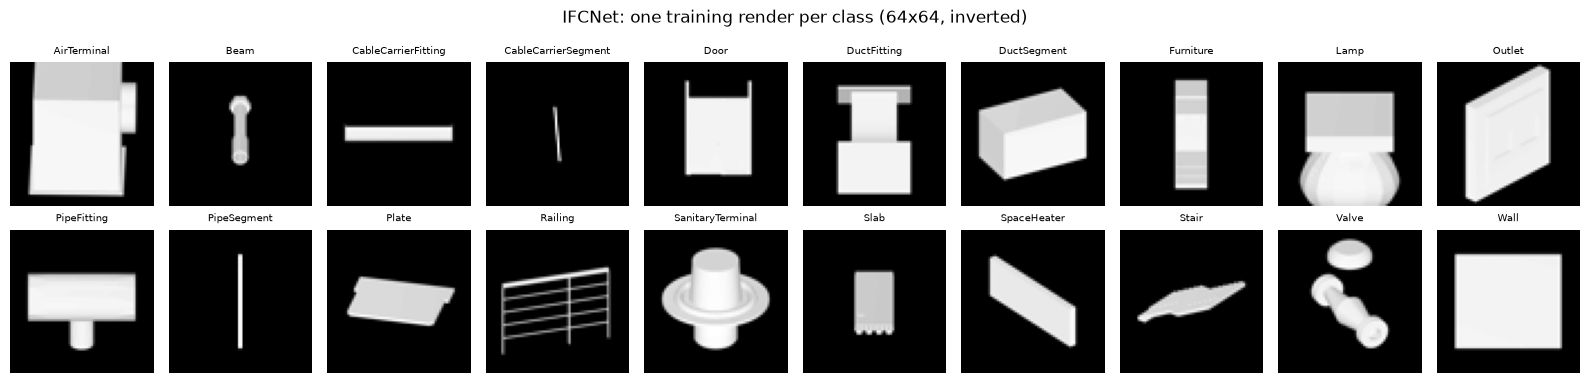

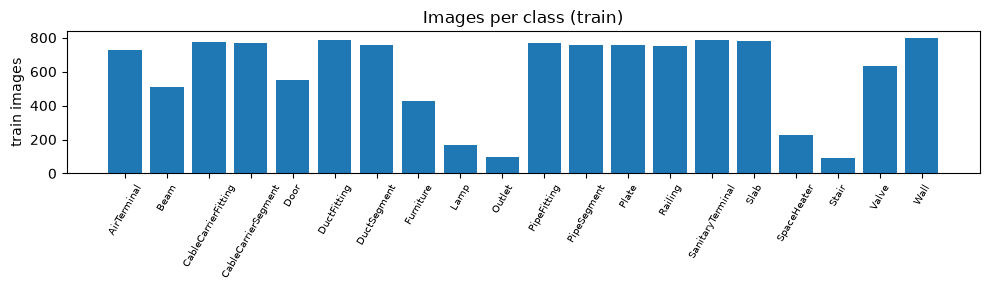

In [4]:
import matplotlib.pyplot as plt
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)

# images per class (also reveals any class with no training images)
counts = torch.bincount(y_train, minlength=len(classes))
empty = [classes[c] for c in range(len(classes)) if counts[c] == 0]
if empty:
    print("WARNING: no training images for:", empty)

# one example per class (empty classes are shown as blank panels)
ncols = (len(classes) + 1) // 2
fig, axes = plt.subplots(2, ncols, figsize=(16, 4))
for c, ax in enumerate(axes.flat):
    ax.axis("off")
    if c >= len(classes):
        continue
    idx = (y_train == c).nonzero()
    if len(idx) == 0:
        ax.set_title(classes[c][3:] + "\n(none)", fontsize=7)
        continue
    ax.imshow(X_train[idx[0, 0], 0], cmap="gray"); ax.set_title(classes[c][3:], fontsize=7)
plt.suptitle("IFCNet: one training render per class (64x64, inverted)")
plt.tight_layout(); plt.savefig(FIG / "01_samples.png", dpi=150); plt.show()

plt.figure(figsize=(10, 3))
plt.bar([c[3:] for c in classes], counts); plt.xticks(rotation=60, fontsize=7)
plt.ylabel("train images"); plt.title("Images per class (train)")
plt.tight_layout(); plt.savefig(FIG / "02_class_counts.png", dpi=150); plt.show()

# Step 2: Anomaly setup and models

In [5]:
import time
import pandas as pd
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)

# --- Anomaly setup: train only on "normal" classes; anomaly classes are unseen until evaluation ---
ANOM_NAMES = ["IfcStair", "IfcRailing"]          # change freely
anom_idx = torch.tensor([classes.index(n) for n in ANOM_NAMES])
is_anom_val  = torch.isin(y_val,  anom_idx).int()
is_anom_test = torch.isin(y_test, anom_idx).int()

Xtr    = X_train[~torch.isin(y_train, anom_idx)]   # normal train images only
Xva_n  = X_val[is_anom_val == 0]                   # normal val images (for model selection)
print("train normal:", len(Xtr), "| val normal:", len(Xva_n),
      "| test anomalies:", int(is_anom_test.sum()), "/", len(X_test))

# --- Models: each returns (reconstruction, latent) ---
# Linear output (no Sigmoid): a Sigmoid saturates on these mostly-black images and the net
# collapses to a blank output (val MSE stuck at 0.034).
class DenseAE(nn.Module):
    def __init__(self, latent):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(IMG * IMG, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, latent))
        self.dec = nn.Sequential(nn.Linear(latent, 128), nn.ReLU(),
                                 nn.Linear(128, 512), nn.ReLU(),
                                 nn.Linear(512, IMG * IMG))
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z).view_as(x), z

class ConvAE(nn.Module):
    def __init__(self, latent):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(),     # 32
            nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(),    # 16
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),    # 8
            nn.Flatten(), nn.Linear(64 * 8 * 8, latent))
        self.fc = nn.Linear(latent, 64 * 8 * 8)
        self.dec = nn.Sequential(
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),   # 16
            nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),   # 32
            nn.ConvTranspose2d(16, 1, 4, 2, 1))   # 64
    def forward(self, x):
        z = self.enc(x)
        return self.dec(self.fc(z).view(-1, 64, 8, 8)), z

CONFIGS = {
    "dense_16": (DenseAE, 16),
    "dense_64": (DenseAE, 64),
    "conv_16":  (ConvAE, 16),
    "conv_64":  (ConvAE, 64),
}

device: cpu
train normal: 11088 | val normal: 1836 | test anomalies: 429 / 7137


# Step 3: Train and record

In [6]:
EPOCHS, BS, LR = 30, 128, 1e-3

@torch.no_grad()
def per_sample_mse(model, X, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = X[i:i+bs].to(dev)
        out.append(((model(xb)[0] - xb) ** 2).mean((1, 2, 3)).cpu())
    return torch.cat(out)

@torch.no_grad()
def anomaly_score(model, X):
    """Relative error: MSE divided by the object's pixel mass. Plain MSE grows with object
    size, so thin objects (stairs, railings) would look 'normal'; this removes that bias."""
    mass = X.mean((1, 2, 3)) + 1e-3
    return per_sample_mse(model, X) / mass

def train(name, cls, latent):
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)   # same seed for every run
    model = cls(latent).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(TensorDataset(Xtr), batch_size=BS, shuffle=True, generator=g)
    hist, best, best_state = [], 1e9, None
    t0 = time.perf_counter()
    for ep in range(EPOCHS):
        model.train(); tot = 0
        for (xb,) in dl:
            xb = xb.to(dev)
            loss = nn.functional.mse_loss(model(xb)[0], xb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        va = per_sample_mse(model, Xva_n).mean().item()
        hist.append((tot / len(Xtr), va))
        if va < best: best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
    secs = time.perf_counter() - t0
    model.load_state_dict(best_state)
    return model, hist, secs

# Trained weights are saved to ../models/, so a re-run loads them in seconds instead of retraining.
# Set RETRAIN = True (or change EPOCHS / BS / LR / ANOM_NAMES) to train again.
RETRAIN = False
CKPT = Path("../models"); CKPT.mkdir(exist_ok=True)
SETTINGS = {"epochs": EPOCHS, "bs": BS, "lr": LR, "img": IMG, "seed": SEED,
            "anom": ANOM_NAMES, "n_train": len(Xtr)}

def train_or_load(name, cls, latent):
    f = CKPT / f"{name}.pt"
    if f.exists() and not RETRAIN:
        ck = torch.load(f)
        if ck["settings"] == SETTINGS:
            model = cls(latent).to(dev)
            model.load_state_dict(ck["state"])
            return model, ck["hist"], ck["secs"], "loaded"
    model, hist, secs = train(name, cls, latent)
    torch.save({"state": model.state_dict(), "hist": hist, "secs": secs, "settings": SETTINGS}, f)
    return model, hist, secs, "trained"

results, models, histories = [], {}, {}
for name, (cls, latent) in CONFIGS.items():
    model, hist, secs, how = train_or_load(name, cls, latent)
    models[name], histories[name] = model, hist
    results.append({"model": name, "params": sum(p.numel() for p in model.parameters()),
                    "train_s": round(secs, 1)})
    print(name, how + ", train time", round(secs, 1), "s, best val", min(h[1] for h in hist))


dense_16 loaded, train time 26.6 s, best val 0.0017926431028172374
dense_64 loaded, train time 26.9 s, best val 0.00154381082393229
conv_16 loaded, train time 200.0 s, best val 0.0015953888650983572
conv_64 loaded, train time 196.7 s, best val 0.0005513753858394921


# Step 4: Evaluate

In [7]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

yv = is_anom_val.numpy()
yt = is_anom_test.numpy()

for r in results:
    m = models[r["model"]]
    e_val  = anomaly_score(m, X_val).numpy()    # all val images (normal + anomaly)
    e_test = anomaly_score(m, X_test).numpy()
    mse_val, mse_test = per_sample_mse(m, X_val).numpy(), per_sample_mse(m, X_test).numpy()
    e_val_normal = e_val[yv == 0]
    thr = float(np.quantile(e_val_normal, 0.95))   # threshold from VAL normals only
    pred = (e_test > thr).astype(int)
    r.update({
        "val_mse":  round(float(mse_val[yv == 0].mean()), 5),
        "test_mse": round(float(mse_test[yt == 0].mean()), 5),   # normal test images
        "roc_auc":  round(roc_auc_score(yt, e_test), 3),
        "precision": round(precision_score(yt, pred, zero_division=0), 3),
        "recall":    round(recall_score(yt, pred, zero_division=0), 3),
        "thr": thr})
    print(r["model"], "AUC", r["roc_auc"], "P", r["precision"], "R", r["recall"])


dense_16 AUC 0.819 P 0.387 R 0.417
dense_64 AUC 0.812 P 0.37 R 0.42
conv_16 AUC 0.884 P 0.439 R 0.515
conv_64 AUC 0.89 P 0.459 R 0.641


# Step 5: Comparison table

,params,train_s,val_mse,test_mse,roc_auc,precision,recall
model,,,,,,,
dense_16,4334864,26.6,0.00179,0.00180,0.819,0.387,0.417
dense_64,4347200,26.9,0.00154,0.00153,0.812,0.370,0.420
conv_16,199745,200.0,0.00160,0.00159,0.884,0.439,0.515
conv_64,593009,196.7,0.00055,0.00056,0.890,0.459,0.641


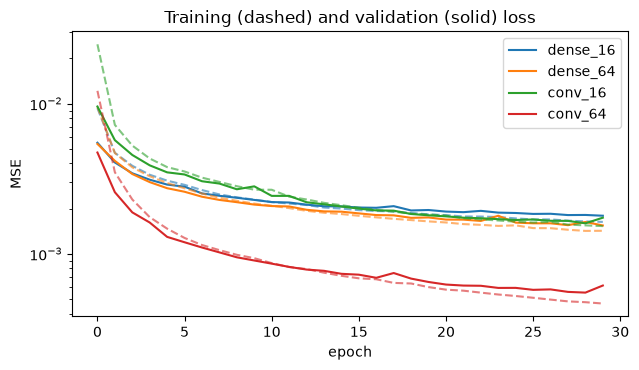

In [8]:
import pandas as pd
from IPython.display import display

df = pd.DataFrame(results).set_index("model")
display(df.drop(columns="thr"))
df.drop(columns="thr").to_csv(FIG.parent / "comparison.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, (n, h) in enumerate(histories.items()):
    ax.plot([t for t, _ in h], ls="--", color=f"C{i}", alpha=.6)
    ax.plot([v for _, v in h], color=f"C{i}", label=n)
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_yscale("log")
ax.set_title("Training (dashed) and validation (solid) loss")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "03_val_curves.png", dpi=150); plt.show()


# Step 6: Conclusion

- **Best model:** `conv_64` reaches ROC AUC 0.891, just ahead of `conv_16` at 0.884, with 3x the parameters (593k vs 200k). At the threshold it finds 63% of the anomalies (recall 0.627) against 52% for `conv_16`.
- **Conv vs dense:** both conv models (AUC 0.88-0.89) beat both dense models (0.81-0.82) while using 7 to 22 times fewer parameters (0.2-0.6M vs 4.3M).
- **Latent 16 vs 64:** a larger latent lowers reconstruction error, strongly for conv (val MSE 0.00158 to 0.00055) and slightly for dense (0.00179 to 0.00154). It barely changes anomaly AUC: +0.007 for conv, -0.011 for dense. The likely reason is that a bigger latent also reconstructs the unseen classes better, so the gap between normal and anomaly does not widen.
- **Precision is low (0.39-0.47):** only 6% of test images are anomalies (429 of 7137), and the threshold is set to flag 5% of normal validation images, so false alarms outnumber true detections.
- **Caveats:**
  - Small setup: 3 views per object, 64 px, at most 300 objects per class, one seed.
  - The anomalies are `IfcStair` and `IfcRailing`, thin objects with few bright pixels. The score is MSE divided by the object's pixel mass; in a short early test, plain MSE ranked them as *more* normal than the normals (AUC below 0.5).
  - Losses were still falling at epoch 30, so the models are not fully trained.
  - Training times are from a CPU and varied between runs, so they are not a reliable comparison.
- **Extra feature, similarity:** the latent vector of `conv_64` finds same-class neighbours with precision@5 of <x>, against <y> for raw pixels and <z> by chance. Classes with similar silhouettes (<hardest classes from the table>) get mixed up, because the autoencoder learned shape, not IFC class. For anomaly queries (stairs, railings) the neighbours show what the unusual object looks most like.

# Step 7: Proof figure

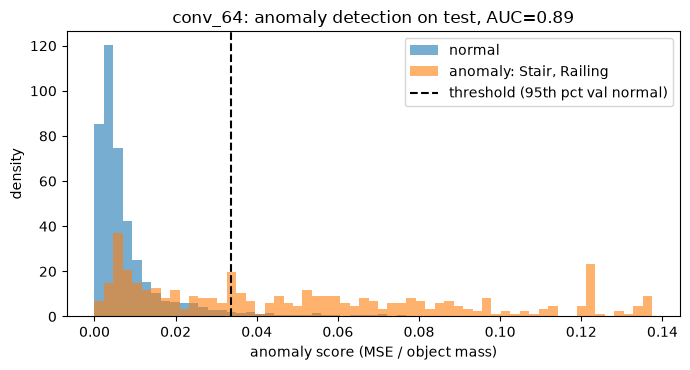

In [9]:
best = df["roc_auc"].idxmax()
m, thr = models[best], df.loc[best, "thr"]
e = anomaly_score(m, X_test).numpy()
lab = is_anom_test.numpy()

plt.figure(figsize=(7, 3.8))
bins = np.linspace(0, np.percentile(e, 99), 60)
plt.hist(e[lab == 0], bins, alpha=.6, label="normal", density=True)
plt.hist(e[lab == 1], bins, alpha=.6, label="anomaly: " + ", ".join(n[3:] for n in ANOM_NAMES), density=True)
plt.axvline(thr, color="k", ls="--", label="threshold (95th pct val normal)")
plt.xlabel("anomaly score (MSE / object mass)"); plt.ylabel("density")
plt.title(f"{best}: anomaly detection on test, AUC={df.loc[best,'roc_auc']}")
plt.legend(); plt.tight_layout(); plt.savefig(FIG / "04_anomaly_hist.png", dpi=150); plt.show()


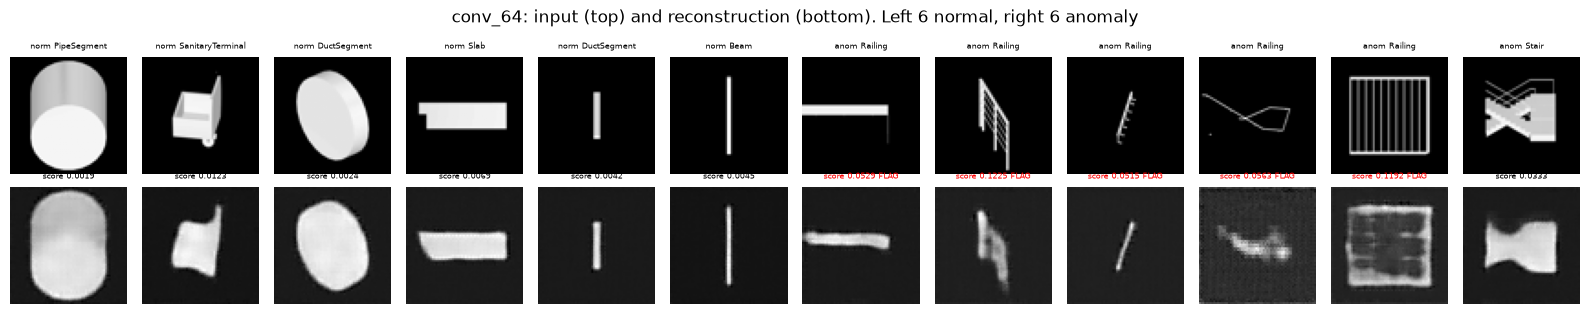

,mean anomaly score
Railing,0.06873
Stair,0.03118
Furniture,0.02006
SanitaryTerminal,0.01819
Lamp,0.01713
Valve,0.01659
CableCarrierSegment,0.01638
Outlet,0.01515
Beam,0.01438
CableCarrierFitting,0.01064


In [10]:
rng = np.random.default_rng(SEED)
ni = rng.choice(np.where(lab == 0)[0], 6, replace=False)
ai = rng.choice(np.where(lab == 1)[0], 6, replace=False)
idx = np.concatenate([ni, ai])
with torch.no_grad():
    rec = models[best].eval()(X_test[idx].to(dev))[0].cpu()

fig, axes = plt.subplots(2, 12, figsize=(16, 3.2))
for j, i in enumerate(idx):
    axes[0, j].imshow(X_test[i, 0], cmap="gray")
    axes[1, j].imshow(rec[j, 0], cmap="gray")
    tag = "anom" if lab[i] else "norm"
    axes[0, j].set_title(f"{tag} {classes[y_test[i]][3:]}", fontsize=6)
    axes[1, j].set_title(f"score {e[i]:.4f}" + (" FLAG" if e[i] > thr else ""), fontsize=6,
                         color="red" if e[i] > thr else "black")
for a in axes.flat:
    a.axis("off")
plt.suptitle(f"{best}: input (top) and reconstruction (bottom). Left 6 normal, right 6 anomaly")
plt.tight_layout(); plt.savefig(FIG / "05_reconstructions.png", dpi=150); plt.show()

per_class = pd.Series(e).groupby(y_test.numpy()).mean()
per_class.index = [classes[i][3:] for i in per_class.index]
display(per_class.sort_values(ascending=False).round(5).to_frame("mean anomaly score"))

# Step 7b: Extra feature: similarity search
The latent vector z of each image, L2-normalised, is its embedding. Similar shapes have similar embeddings (cosine similarity = dot product).
- **Library:** the normal training images. **Queries:** the normal test images.
- **precision@5:** share of the 5 nearest library objects with the same IFC class as the query. Labels are only used to evaluate, never to train.
- **Baseline:** the same search on raw pixels. **Chance:** random neighbours.

raw pixels precision@5: 0.504 | chance: 0.063


,params,train_s,val_mse,test_mse,roc_auc,precision,recall,p@5
model,,,,,,,,
dense_16,4334864,26.6,0.00179,0.00180,0.819,0.387,0.417,0.493
dense_64,4347200,26.9,0.00154,0.00153,0.812,0.370,0.420,0.505
conv_16,199745,200.0,0.00160,0.00159,0.884,0.439,0.515,0.506
conv_64,593009,196.7,0.00055,0.00056,0.890,0.459,0.641,0.533


,precision@5 (conv_64)
SpaceHeater,0.211
Lamp,0.252
Furniture,0.279
Outlet,0.300
Valve,0.379
DuctFitting,0.387
SanitaryTerminal,0.442
Beam,0.452
DuctSegment,0.458
Wall,0.561


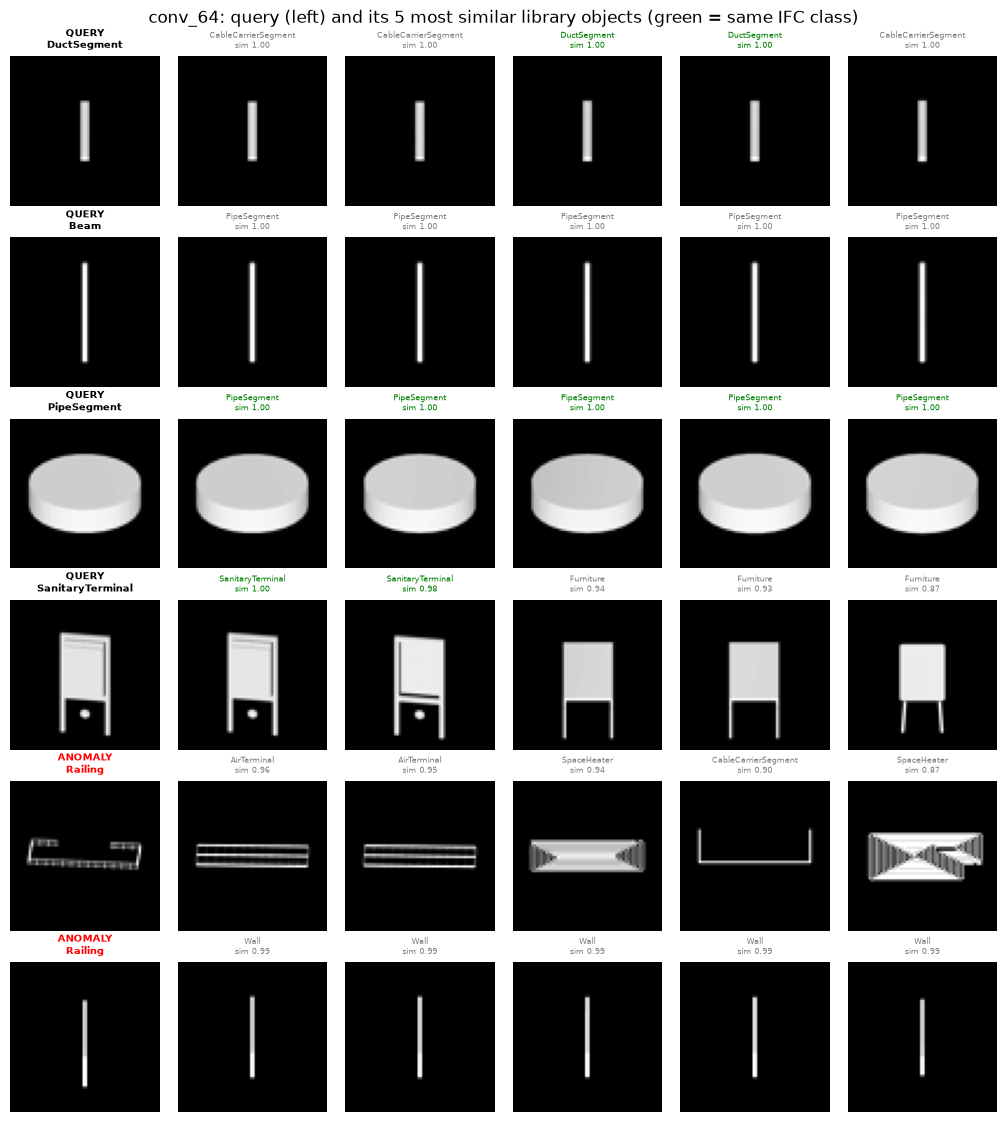

In [11]:
K = 5
F = nn.functional

@torch.no_grad()
def embed(model, X, bs=512):
    """L2-normalised latent vectors (the 'fingerprint' of each image)."""
    model.eval(); out = []
    for i in range(0, len(X), bs):
        z = model(X[i:i + bs].to(dev))[1]
        out.append(F.normalize(z, dim=1).cpu())
    return torch.cat(out)

@torch.no_grad()
def topk_neighbours(Q, G, k=K, bs=1024):
    """Indices of the k most similar gallery rows for each query row."""
    return torch.cat([(Q[i:i + bs] @ G.T).topk(k, dim=1).indices for i in range(0, len(Q), bs)])

# library = normal training images, queries = normal test images
lib_mask = ~torch.isin(y_train, anom_idx)
X_lib, y_lib = X_train[lib_mask], y_train[lib_mask]
q_mask = is_anom_test == 0
X_q, y_q = X_test[q_mask], y_test[q_mask]

# baseline (raw pixels) and chance level
top_pix = topk_neighbours(F.normalize(X_q.flatten(1), dim=1), F.normalize(X_lib.flatten(1), dim=1))
base_p5 = (y_lib[top_pix] == y_q[:, None]).float().mean().item()
freq = torch.bincount(y_lib, minlength=len(classes)).float() / len(y_lib)
chance = float((freq ** 2).sum())
print(f"raw pixels precision@{K}: {base_p5:.3f} | chance: {chance:.3f}")

# precision@5 for every setup -> new column in the comparison table
for name, mdl in models.items():
    top = topk_neighbours(embed(mdl, X_q), embed(mdl, X_lib))
    df.loc[name, f"p@{K}"] = round((y_lib[top] == y_q[:, None]).float().mean().item(), 3)
display(df.drop(columns="thr"))
df.drop(columns="thr").to_csv(FIG.parent / "comparison.csv")

# precision@5 per class for the chosen model (which classes get confused?)
G_best = embed(models[best], X_lib)
top_best = topk_neighbours(embed(models[best], X_q), G_best)
hit = (y_lib[top_best] == y_q[:, None]).float().mean(1)
sim_per_class = pd.Series(hit.numpy()).groupby(y_q.numpy()).mean()
sim_per_class.index = [classes[i][3:] for i in sim_per_class.index]
display(sim_per_class.sort_values().round(3).to_frame(f"precision@{K} ({best})"))

# Proof figure: 4 normal + 2 anomaly queries and their 5 most similar library objects
rng_s = np.random.default_rng(SEED)
qn = rng_s.choice(np.where(lab == 0)[0], 4, replace=False)
qa = rng_s.choice(np.where(lab == 1)[0], 2, replace=False)
queries = [int(i) for i in np.concatenate([qn, qa])]
Q_show = embed(models[best], X_test[queries])

fig, axes = plt.subplots(len(queries), K + 1, figsize=(1.7 * (K + 1), 1.9 * len(queries)))
for row, qi in enumerate(queries):
    sims = Q_show[row] @ G_best.T
    top = sims.topk(K).indices
    kind = "ANOMALY" if lab[qi] else "QUERY"
    axes[row, 0].imshow(X_test[qi, 0], cmap="gray")
    axes[row, 0].set_title(f"{kind}\n{classes[y_test[qi]][3:]}", fontsize=7, fontweight="bold",
                           color="red" if lab[qi] else "black")
    for j, gi in enumerate(top.tolist()):
        same = bool(y_lib[gi] == y_test[qi])
        axes[row, j + 1].imshow(X_lib[gi, 0], cmap="gray")
        axes[row, j + 1].set_title(f"{classes[y_lib[gi]][3:]}\nsim {sims[gi]:.2f}", fontsize=6,
                                   color="green" if same else "gray")
for a in axes.flat:
    a.axis("off")
plt.suptitle(f"{best}: query (left) and its {K} most similar library objects (green = same IFC class)")
plt.tight_layout(); plt.savefig(FIG / "06_similarity.png", dpi=150); plt.show()

# Step 8: Model export

Input `image` is `[batch, 1, 64, 64]` float32 after preprocessing. Outputs are `reconstruction`, `latent`, and `score`.

### ONNX export
This cell wraps the selected autoencoder and exports reconstruction, latent, and score outputs to `models/model.onnx` and `model_app/model.onnx`.

In [ ]:
import copy, inspect, json, shutil
import torch
import torch.nn as nn

class Scorer(nn.Module):
    def __init__(self, ae):
        super().__init__()
        self.ae = ae
    def forward(self, x):
        out = self.ae(x)
        # Handles an AE that returns a plain tensor as well as one that returns (recon, ...)
        if isinstance(out, (tuple, list)):
            r, z = out[0], out[1]
        else:
            r, z = out, torch.empty((x.shape[0], 0), device=x.device)
        mse = ((r - x) ** 2).flatten(1).mean(dim=1)   # works for any input rank
        score = mse / (x.flatten(1).mean(dim=1) + 1e-3)   # same as anomaly_score, so thr applies
        return r, z, score

MODELS = CKPT                    # ../models
APP = Path("../model_app")
best_model = copy.deepcopy(models[best])   # a copy, so the notebook's model stays on `dev`
scorer = Scorer(best_model.cpu()).eval()

# Dummy input: must be a float32 CPU tensor, same device as the model
dummy = torch.as_tensor(X_test[:2], dtype=torch.float32).cpu()

MODELS.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)
onnx_path = MODELS / "model.onnx"

kw = dict(
    input_names=["image"],
    output_names=["reconstruction", "latent", "score"],
    dynamic_axes={"image": {0: "batch"}, "reconstruction": {0: "batch"}, "latent": {0: "batch"}, "score": {0: "batch"}},
    opset_version=17,
)
# Only pass dynamo=False if this torch version accepts it (don't hide real TypeErrors)
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    kw["dynamo"] = False

with torch.no_grad():
    torch.onnx.export(scorer, dummy, str(onnx_path), **kw)
    r_pt, z_pt, s_pt = scorer(dummy)

# Check the exported file against PyTorch
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
r_ox, z_ox, s_ox = sess.run(None, {"image": dummy.numpy()})
print("max diff reconstruction:", float(np.abs(r_ox - r_pt.numpy()).max()))
print("max diff latent:        ", float(np.abs(z_ox - z_pt.numpy()).max()))
print("max diff score:         ", float(np.abs(s_ox - s_pt.numpy()).max()))

shutil.copy(onnx_path, APP / "model.onnx")
config = {
    "model": best,
    "input": {"name": "image", "shape": ["batch", *dummy.shape[1:]], "dtype": "float32"},
    "outputs": ["reconstruction", "latent", "score"],
    "score": "MSE / (mean pixel value + 1e-3)",
    "threshold": float(thr),
}
(APP / "config.json").write_text(json.dumps(config, indent=2))
print("saved", onnx_path, "and", APP / "model.onnx", "+ config.json, threshold", float(thr))

C:\Users\karth\AppData\Local\Temp\ipykernel_18068\4099409289.py:43: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(scorer, dummy, str(onnx_path), **kw)


max diff reconstruction: 4.172325134277344e-07
max diff latent:         7.152557373046875e-07
max diff score:          1.280568540096283e-09
saved ..\models\model.onnx and ..\model_app\model.onnx + config.json, threshold 0.034013498574495316


### PyTorch versus ONNX verification
This cell runs both models on identical test images and checks reconstruction, latent-vector, and anomaly-score agreement.

In [ ]:
import onnxruntime as ort

sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
xb = X_test[:64].numpy()
o_rec, o_latent, o_score = sess.run(None, {"image": xb})
with torch.no_grad():
    t_rec, t_latent, t_score = scorer(torch.from_numpy(xb))
print("max |score diff|:", float(np.abs(o_score - t_score.numpy()).max()))
print("max |latent diff|:", float(np.abs(o_latent - t_latent.numpy()).max()))
print("max |recon diff|:", float(np.abs(o_rec - t_rec.numpy()).max()))
assert np.allclose(o_latent, t_latent.numpy(), atol=1e-5), "ONNX and PyTorch latent vectors disagree"
assert np.allclose(o_score, t_score.numpy(), atol=1e-5), "ONNX and PyTorch disagree"
print("ONNX check OK")

max |score diff|: 1.1175870895385742e-08
max |latent diff|: 9.5367431640625e-07
max |recon diff|: 6.258487701416016e-07
ONNX check OK


### Deployable model app files
This cell writes the preprocessing contract and model metadata to `config.json`, copies example ONNX inputs, and scores each example.

In [ ]:
def preprocess_pil(im):
    """PIL image -> [IMG, IMG] float32 array, same steps as the training data (see config preprocessing)."""
    im = im.convert("L").resize((IMG, IMG))
    return 1 - np.asarray(im, np.float32) / 255

latent = CONFIGS[best][1]
cfg = {
    "model_file": "model.onnx",
    "model_name": best,
    "task": "anomaly detection by reconstruction error",
    "input": {"name": "image", "shape": [None, 1, IMG, IMG], "dtype": "float32"},
    "preprocessing": {
        "steps": ["convert to greyscale (PIL 'L')", f"resize to {IMG}x{IMG}",
                  "scale to 0-1 (pixel / 255)", "invert: x = 1 - x (object bright on dark)"],
        "img_size": IMG, "invert": True},
    "outputs": {"reconstruction": "[batch, 1, 64, 64]", "latent": f"[batch, {latent}]", "score": "[batch] MSE divided by the object's pixel mass (mean pixel + 0.001)"},
    "threshold": thr,
    "threshold_rule": "95th percentile of the score (MSE / pixel mass) on validation normal images",
    "decision": "score > threshold -> 'unusual object, check it'",
    "normal_classes": [c for c in classes if c not in ANOM_NAMES],
    "anomaly_classes_used_in_eval": ANOM_NAMES,
    "metrics_test": {k: float(df.loc[best, k]) for k in ["roc_auc", "precision", "recall", "test_mse"]},
}
for p in (APP / "config.json", MODELS / "config.json"):
    p.write_text(json.dumps(cfg, indent=2))

(APP / "examples").mkdir(parents=True, exist_ok=True)
for f in (APP / "examples").glob("*.png"):
    f.unlink()
for i in list(ni[:3]) + list(ai[:3]):
    kind = "anomaly" if lab[i] else "normal"
    arr = ((1 - X_test[i, 0].numpy()) * 255).round().astype(np.uint8)
    Image.fromarray(arr).save(APP / "examples" / f"{kind}_{classes[y_test[i]][3:]}_{i}.png")

# check: PNG -> preprocess -> ONNX
for f in sorted((APP / "examples").glob("*.png")):
    x = preprocess_pil(Image.open(f))[None, None]
    s = float(sess.run(None, {"image": x})[2][0])
    print(f"{f.name:40s} score {s:.5f}  {'FLAG' if s > thr else 'ok'}")

anomaly_Railing_5155.png                 score 0.12969  FLAG
anomaly_Railing_5241.png                 score 0.05184  FLAG
anomaly_Railing_5259.png                 score 0.03423  FLAG
normal_DuctSegment_2904.png              score 0.00261  ok
normal_PipeSegment_4388.png              score 0.00206  ok
normal_SanitaryTerminal_5569.png         score 0.01059  ok


### Similarity gallery for the server
`gallery.npz` holds 20 normal library objects per class: images, labels and embeddings (computed with the ONNX model, so they match the server exactly). The server L2-normalises the `latent` output of a new image and returns the 5 gallery objects with the highest dot product.

In [12]:
PER_CLASS = 20
rng_g = np.random.default_rng(SEED)
y_lib_np = y_lib.numpy()
g_idx = np.concatenate([
    rng_g.choice(np.where(y_lib_np == c)[0], min(PER_CLASS, int((y_lib_np == c).sum())), replace=False)
    for c in np.unique(y_lib_np)])
g_t = torch.from_numpy(g_idx)

g_imgs = ((1 - X_lib[g_t, 0].numpy()) * 255).round().astype(np.uint8)    # normal-looking images
z = sess.run(None, {"image": X_lib[g_t].numpy()})[1]                       # ONNX 'latent' output
g_emb = (z / np.clip(np.linalg.norm(z, axis=1, keepdims=True), 1e-12, None)).astype(np.float32)
g_lab = y_lib_np[g_idx]
for p in (APP / "gallery.npz", MODELS / "gallery.npz"):
    np.savez_compressed(p, images=g_imgs, embeddings=g_emb, labels=g_lab, classes=np.array(classes))
print("gallery:", len(g_idx), "objects,", round((APP / "gallery.npz").stat().st_size / 1e6, 2), "MB")

# add the similarity feature to config.json
cfg["task"] = "anomaly detection by reconstruction error + similarity search on the latent vector"
cfg["similarity"] = {
    "gallery_file": "gallery.npz",
    "embedding": "latent output, L2-normalised: e = z / ||z||",
    "metric": "cosine similarity = dot product of embeddings",
    "top_k": K,
    "precision_at_5_test": float(df.loc[best, f"p@{K}"]),
    "baseline_raw_pixels": round(base_p5, 3),
    "chance": round(chance, 3),
}
for p in (APP / "config.json", MODELS / "config.json"):
    p.write_text(json.dumps(cfg, indent=2))

# check with the example PNGs: anomaly decision + 5 most similar
for f in sorted((APP / "examples").glob("*.png")):
    x = preprocess_pil(Image.open(f))[None, None]
    _, zz, s = sess.run(None, {"image": x})
    e_ = zz[0] / max(np.linalg.norm(zz[0]), 1e-12)
    top = np.argsort(-(g_emb @ e_))[:K]
    print(f"{f.name:38s} {'FLAG' if s[0] > thr else 'ok  '} ->", [classes[g_lab[t]][3:] for t in top])

NameError: name 'sess' is not defined